In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data/processed/pm25_forecasting.csv",
    parse_dates=["date", "target_date"]
)

print("Total observations:", len(df))
print("Unique stations:", df["station_id"].nunique())
print("Date range:", df["date"].min(), df["date"].max())


Total observations: 8283
Unique stations: 97
Date range: 2025-07-01 00:00:00 2025-09-29 00:00:00


In [2]:


# Training targets: July and August
train = df[
    df["target_date"] < "2025-09-01"
].copy()

# Test targets: September
test = df[
    df["target_date"] >= "2025-09-01"
].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training target range:")
print(train["target_date"].min(), train["target_date"].max())

print("Testing target range:")
print(test["target_date"].min(), test["target_date"].max())


Training observations: 5558
Testing observations: 2725
Training target range:
2025-07-02 00:00:00 2025-08-31 00:00:00
Testing target range:
2025-09-01 00:00:00 2025-09-30 00:00:00


In [3]:

base_features = ["pm25"]

fire_features = [
    "pm25",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km"
]

y_train = train["target_pm25"]
y_test = test["target_pm25"]

# Model A: Persistence
pred_persistence = test["pm25"].to_numpy()

# Model B: Random Forest using PM2.5 only
rf_base = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_base.fit(train[base_features], y_train)
pred_rf_base = rf_base.predict(test[base_features])

# Model C: Random Forest with wildfire features
rf_fire = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_fire.fit(train[fire_features], y_train)
pred_rf_fire = rf_fire.predict(test[fire_features])

# Evaluation
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

results = pd.DataFrame([
    evaluate(
        "Persistence",
        y_test,
        pred_persistence
    ),
    evaluate(
        "RF - PM2.5 only",
        y_test,
        pred_rf_base
    ),
    evaluate(
        "RF - PM2.5 + Fire",
        y_test,
        pred_rf_fire
    )
])

display(results.round(3))


,Model,MAE,RMSE
0,Persistence,2.577,11.482
1,RF - PM2.5 only,2.422,11.383
2,RF - PM2.5 + Fire,2.485,11.449


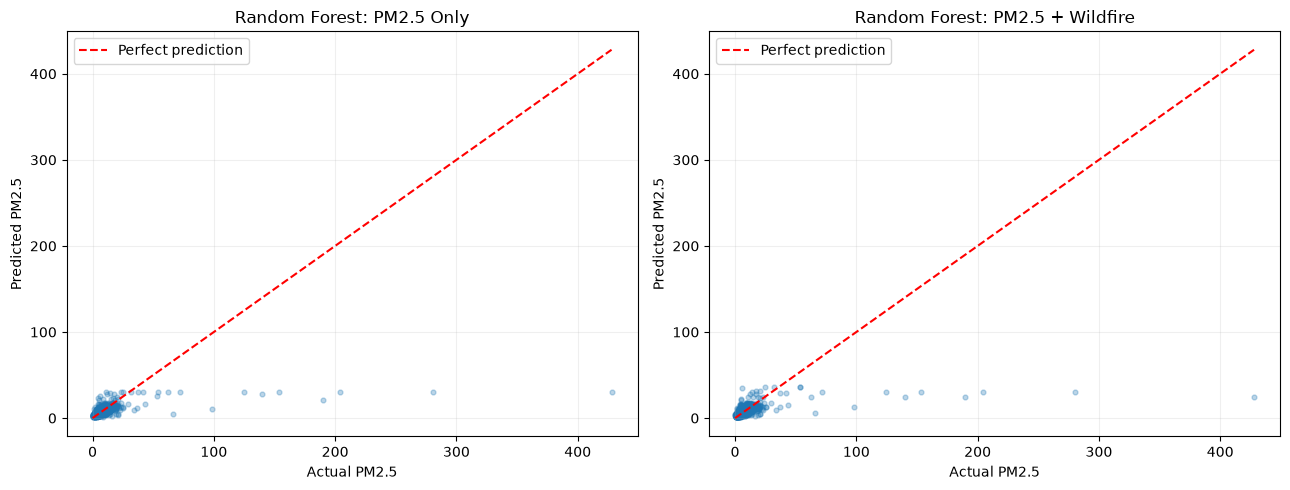

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Random Forest without fires
axes[0].scatter(
    y_test,
    pred_rf_base,
    alpha=0.3,
    s=12
)

axes[0].set_title("Random Forest: PM2.5 Only")
axes[0].set_xlabel("Actual PM2.5")
axes[0].set_ylabel("Predicted PM2.5")

# Random Forest with wildfire features
axes[1].scatter(
    y_test,
    pred_rf_fire,
    alpha=0.3,
    s=12
)

axes[1].set_title("Random Forest: PM2.5 + Wildfire")
axes[1].set_xlabel("Actual PM2.5")
axes[1].set_ylabel("Predicted PM2.5")

# Reference lines
limits = [
    0,
    max(
        y_test.max(),
        pred_rf_base.max(),
        pred_rf_fire.max()
    )
]

for ax in axes:
    ax.plot(limits, limits, "r--", label="Perfect prediction")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [5]:

output_dir = project_dir / "experiments"
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    output_dir / "baseline_model_results.csv",
    index=False
)

print("Results saved successfully!")


Results saved successfully!


In [6]:

# Create prediction comparison dataframe
error_analysis = test[
    ["station_id", "date", "target_date",
     "pm25", "target_pm25"]
].copy()

error_analysis["persistence_pred"] = pred_persistence
error_analysis["rf_base_pred"] = pred_rf_base
error_analysis["rf_fire_pred"] = pred_rf_fire

# Absolute prediction errors
error_analysis["base_error"] = abs(
    error_analysis["target_pm25"]
    - error_analysis["rf_base_pred"]
)

error_analysis["fire_error"] = abs(
    error_analysis["target_pm25"]
    - error_analysis["rf_fire_pred"]
)

# Did the fire model improve?
error_analysis["fire_improvement"] = (
    error_analysis["base_error"]
    - error_analysis["fire_error"]
)

print("Largest errors from the wildfire model:")

display(
    error_analysis.nlargest(
        15, "fire_error"
    )
)


Largest errors from the wildfire model:


,station_id,date,target_date,pm25,target_pm25,persistence_pred,rf_base_pred,rf_fire_pred,base_error,fire_error,fire_improvement
2875,06-051-0005,2025-09-07,2025-09-08,139.9,427.9,139.9,29.853481,24.743695,398.046519,403.156305,-5.109787
1254,06-027-0002,2025-09-07,2025-09-08,189.8,280.5,189.8,29.853481,30.266023,250.646519,250.233977,0.412541
1554,06-027-1033,2025-09-07,2025-09-08,98.3,204.4,98.3,29.853481,30.815997,174.546519,173.584003,0.962516
1253,06-027-0002,2025-09-06,2025-09-07,23.1,189.8,23.1,21.330638,24.655217,168.469362,165.144783,3.324580
1255,06-027-0002,2025-09-08,2025-09-09,280.5,153.6,280.5,29.853481,30.266023,123.746519,123.333977,0.412541
2874,06-051-0005,2025-09-06,2025-09-07,36.9,139.9,36.9,27.778607,24.412514,112.121393,115.487486,-3.366093
1555,06-027-1033,2025-09-08,2025-09-09,204.4,124.6,204.4,29.853481,30.266023,94.746519,94.333977,0.412541
1553,06-027-1033,2025-09-06,2025-09-07,12.3,98.3,12.3,10.877101,12.522683,87.422899,85.777317,1.645581
1436,06-027-1018,2025-09-07,2025-09-08,5.1,66.1,5.1,5.091578,6.204759,61.008422,59.895241,1.113181
1437,06-027-1018,2025-09-08,2025-09-09,66.1,71.8,66.1,29.853481,30.414461,41.946519,41.385539,0.560980


In [7]:

from sklearn.metrics import mean_absolute_error
import pandas as pd

# Define evaluation ranges
ranges = {
    "Low (< 12)": test["target_pm25"] < 12,
    "Moderate (12–35)": test["target_pm25"].between(
        12, 35, inclusive="left"
    ),
    "Elevated (>= 35)": test["target_pm25"] >= 35
}

rows = []

for name, mask in ranges.items():
    actual = y_test[mask]

    if len(actual) == 0:
        continue

    rows.append({
        "PM2.5 Range": name,
        "Samples": len(actual),
        "RF Base MAE": mean_absolute_error(
            actual,
            pred_rf_base[mask.to_numpy()]
        ),
        "RF Fire MAE": mean_absolute_error(
            actual,
            pred_rf_fire[mask.to_numpy()]
        )
    })

range_results = pd.DataFrame(rows)

display(range_results.round(3))


,PM2.5 Range,Samples,RF Base MAE,RF Fire MAE
0,Low (< 12),2512,1.641,1.695
1,Moderate (12–35),196,4.136,4.351
2,Elevated (>= 35),17,98.166,97.611
